# Autoencoder training and evaluation

Fit four autoencoder architectures on normal synthetic traffic, calibrate thresholds on normal validation examples, and evaluate the held-out test set. Saved outputs are retained from the reference execution.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.optimizers import Adam

SEED = 42
DATASET_PATH = "synthetic_network_intrusion_data.csv"

EPOCHS = 100
BATCH_SIZE = 32
LEARNING_RATE = 0.001
BETA_1 = 0.9
BETA_2 = 0.999
EPSILON = 1e-7

tf.keras.utils.set_random_seed(SEED)

if hasattr(tf.config, "experimental") and hasattr(
    tf.config.experimental, "enable_op_determinism"
):
    tf.config.experimental.enable_op_determinism()
elif hasattr(tf.config, "enable_op_determinism"):
    tf.config.enable_op_determinism()

FEATURES = [
    "connections_5s",
    "syn_percentage",
    "avg_connection_duration",
    "unique_dst_ports",
    "transferred_bytes"
]


## 1. Load and validate data


In [2]:
df = pd.read_csv(DATASET_PATH)

required_columns = set(FEATURES + ["attack_type", "label"])
missing_columns = required_columns.difference(df.columns)

if missing_columns:
    raise ValueError(f"Nedostaju kolone: {sorted(missing_columns)}")

if df[FEATURES].isna().sum().sum() != 0:
    raise ValueError("Numeričke karakteristike sadrže nedostajuće vrednosti.")

if not set(df["label"].unique()).issubset({0, 1}):
    raise ValueError("Kolona label može da sadrži samo vrednosti 0 i 1.")

print("Dataset je učitan.")
print("Broj redova:", len(df))
print("\nBroj primera po labeli:")
print(df["label"].value_counts().sort_index())
print("\nBroj primera po tipu saobraćaja:")
print(df["attack_type"].value_counts())


Dataset je učitan.
Broj redova: 1750

Broj primera po labeli:
0    1500
1     250
Name: label, dtype: int64

Broj primera po tipu saobraćaja:
normal       1500
syn_flood     125
port_scan     125
Name: attack_type, dtype: int64


## 2. Split and scale features


In [3]:
normal_df = df[df["label"] == 0].copy()
attack_df = df[df["label"] == 1].copy()

X_normal = normal_df[FEATURES].to_numpy(dtype=np.float32)
X_attack = attack_df[FEATURES].to_numpy(dtype=np.float32)

y_attack = attack_df["label"].to_numpy(dtype=int)
attack_types = attack_df["attack_type"].to_numpy()

# Split normal traffic into 70% training, 15% validation and 15% test.
X_train, X_temp = train_test_split(
    X_normal,
    test_size=0.30,
    random_state=SEED,
    shuffle=True
)

X_val, X_normal_test = train_test_split(
    X_temp,
    test_size=0.50,
    random_state=SEED,
    shuffle=True
)

X_test = np.vstack([X_normal_test, X_attack]).astype(np.float32)
y_test = np.concatenate([
    np.zeros(len(X_normal_test), dtype=int),
    y_attack
])

test_attack_types = np.concatenate([
    np.full(len(X_normal_test), "normal", dtype=object),
    attack_types
])

# Fit the scaler on normal training data only.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train).astype(np.float32)
X_val_scaled = scaler.transform(X_val).astype(np.float32)
X_test_scaled = scaler.transform(X_test).astype(np.float32)

print("Podela podataka:")
print("Trening normalni primeri:", len(X_train_scaled))
print("Validacioni normalni primeri:", len(X_val_scaled))
print("Normalni primeri u testu:", int(np.sum(y_test == 0)))
print("Napadni primeri u testu:", int(np.sum(y_test == 1)))
print("Ukupno u testu:", len(X_test_scaled))


Podela podataka:
Trening normalni primeri: 1050
Validacioni normalni primeri: 225
Normalni primeri u testu: 225
Napadni primeri u testu: 250
Ukupno u testu: 475


In [4]:
scaling_check_df = pd.DataFrame({
    "feature": FEATURES,
    "mean_after_scaling": X_train_scaled.mean(axis=0),
    "std_after_scaling": X_train_scaled.std(axis=0)
})

scaling_check_df.to_csv("scaling_check.csv", index=False)
display(scaling_check_df)


,feature,mean_after_scaling,std_after_scaling
0,connections_5s,1.475925e-08,0.999999
1,syn_percentage,2.678661e-08,1.000000
2,avg_connection_duration,-1.135327e-08,1.000000
3,unique_dst_ports,-1.521338e-08,0.999998
4,transferred_bytes,-2.724784e-09,1.000000


## 3. Model, training and evaluation functions


In [5]:
def create_architecture_name(input_dim, hidden_layers, latent_dim):
    encoder_part = [input_dim] + list(hidden_layers) + [latent_dim]
    decoder_part = list(reversed(hidden_layers)) + [input_dim]
    architecture = encoder_part + decoder_part
    return "-".join(str(value) for value in architecture)


def build_autoencoder(input_dim, hidden_layers=(8, 4), latent_dim=2):
    input_layer = Input(shape=(input_dim,), name="input_layer")

    x = input_layer
    for index, units in enumerate(hidden_layers, start=1):
        x = Dense(
            units,
            activation="relu",
            name=f"encoder_dense_{index}"
        )(x)

    latent = Dense(
        latent_dim,
        activation="relu",
        name="latent_space"
    )(x)

    x = latent
    for index, units in enumerate(reversed(hidden_layers), start=1):
        x = Dense(
            units,
            activation="relu",
            name=f"decoder_dense_{index}"
        )(x)

    output_layer = Dense(
        input_dim,
        activation="linear",
        name="output_layer"
    )(x)

    model = Model(inputs=input_layer, outputs=output_layer)

    model.compile(
        optimizer=Adam(
            learning_rate=LEARNING_RATE,
            beta_1=BETA_1,
            beta_2=BETA_2,
            epsilon=EPSILON
        ),
        loss="mse"
    )

    return model


def reconstruction_errors(model, data):
    reconstructed = model.predict(data, verbose=0)
    return np.mean(np.square(data - reconstructed), axis=1)


def train_unique_model(run_name, hidden_layers, latent_dim):
    # Reset the seed before fitting each distinct architecture.
    tf.keras.utils.set_random_seed(SEED)

    model = build_autoencoder(
        input_dim=X_train_scaled.shape[1],
        hidden_layers=hidden_layers,
        latent_dim=latent_dim
    )

    history = model.fit(
        X_train_scaled,
        X_train_scaled,
        validation_data=(X_val_scaled, X_val_scaled),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        shuffle=False,
        verbose=0
    )

    val_errors = reconstruction_errors(model, X_val_scaled)
    test_errors = reconstruction_errors(model, X_test_scaled)

    train_loss_scaled = float(
        model.evaluate(X_train_scaled, X_train_scaled, verbose=0)
    )
    val_loss_scaled = float(
        model.evaluate(X_val_scaled, X_val_scaled, verbose=0)
    )

    return {
        "run_name": run_name,
        "model": model,
        "history": history,
        "hidden_layers": hidden_layers,
        "latent_dim": latent_dim,
        "architecture": create_architecture_name(
            X_train_scaled.shape[1],
            hidden_layers,
            latent_dim
        ),
        "val_errors": val_errors,
        "test_errors": test_errors,
        "last_epoch_train_loss": float(history.history["loss"][-1]),
        "last_epoch_val_loss": float(history.history["val_loss"][-1]),
        "train_loss_scaled": train_loss_scaled,
        "val_loss_scaled": val_loss_scaled
    }


def evaluate_trained_model(model_name, trained_run, threshold_percentile):
    # Calibrate the threshold on normal validation errors.
    threshold = float(
        np.percentile(trained_run["val_errors"], threshold_percentile)
    )

    test_errors = trained_run["test_errors"]
    y_pred = (test_errors > threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test,
        y_pred,
        labels=[0, 1]
    ).ravel()

    result = {
        "model": model_name,
        "source_run": trained_run["run_name"],
        "architecture": trained_run["architecture"],
        "latent_dim": trained_run["latent_dim"],
        "threshold_percentile": threshold_percentile,
        "threshold": threshold,
        "accuracy": accuracy_score(y_test, y_pred),
        "precision": precision_score(y_test, y_pred, zero_division=0),
        "recall": recall_score(y_test, y_pred, zero_division=0),
        "f1_score": f1_score(y_test, y_pred, zero_division=0),
        "roc_auc": roc_auc_score(y_test, test_errors),
        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn),
        "tp": int(tp),
        "last_epoch_train_loss": trained_run["last_epoch_train_loss"],
        "last_epoch_val_loss": trained_run["last_epoch_val_loss"],
        "train_loss_scaled": trained_run["train_loss_scaled"],
        "val_loss_scaled": trained_run["val_loss_scaled"]
    }

    return {
        "result": result,
        "trained_run": trained_run,
        "test_errors": test_errors,
        "y_pred": y_pred
    }


## 4. Train distinct architectures


In [6]:
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(SEED)

unique_experiments = {
    "base_latent_2": {
        "hidden_layers": (8, 4),
        "latent_dim": 2
    },
    "simple_latent_2": {
        "hidden_layers": (4,),
        "latent_dim": 2
    },
    "base_latent_1": {
        "hidden_layers": (8, 4),
        "latent_dim": 1
    },
    "base_latent_3": {
        "hidden_layers": (8, 4),
        "latent_dim": 3
    }
}

trained_runs = {}

for run_name, settings in unique_experiments.items():
    print("Treniranje:", run_name)
    trained_runs[run_name] = train_unique_model(
        run_name=run_name,
        hidden_layers=settings["hidden_layers"],
        latent_dim=settings["latent_dim"]
    )

    run = trained_runs[run_name]
    print(
        f"  Arhitektura: {run['architecture']} | "
        f"MSE trening: {run['train_loss_scaled']:.6f} | "
        f"MSE validacija: {run['val_loss_scaled']:.6f}"
    )


Treniranje: base_latent_2
  Arhitektura: 5-8-4-2-4-8-5 | MSE trening: 0.533078 | MSE validacija: 0.558354
Treniranje: simple_latent_2
  Arhitektura: 5-4-2-4-5 | MSE trening: 0.605546 | MSE validacija: 0.590215
Treniranje: base_latent_1
  Arhitektura: 5-8-4-1-4-8-5 | MSE trening: 0.734555 | MSE validacija: 0.793987
Treniranje: base_latent_3
  Arhitektura: 5-8-4-3-4-8-5 | MSE trening: 0.591831 | MSE validacija: 0.597069


## 5. Evaluate threshold variants


In [7]:
experiment_results = {
    "Model 1": evaluate_trained_model(
        "Model 1",
        trained_runs["base_latent_2"],
        95
    ),
    "Model 2": evaluate_trained_model(
        "Model 2",
        trained_runs["simple_latent_2"],
        95
    ),
    "Model 3": evaluate_trained_model(
        "Model 3",
        trained_runs["base_latent_2"],
        99
    ),
    "Latent 1": evaluate_trained_model(
        "Latent 1",
        trained_runs["base_latent_1"],
        95
    ),
    "Latent 2": evaluate_trained_model(
        "Latent 2",
        trained_runs["base_latent_2"],
        95
    ),
    "Latent 3": evaluate_trained_model(
        "Latent 3",
        trained_runs["base_latent_3"],
        95
    )
}

for name, data in experiment_results.items():
    result = data["result"]
    print(
        f"{name} | {result['architecture']} | "
        f"prag={result['threshold']:.6f} | "
        f"accuracy={result['accuracy']:.4f} | "
        f"precision={result['precision']:.4f} | "
        f"recall={result['recall']:.4f} | "
        f"F1={result['f1_score']:.4f} | "
        f"ROC-AUC={result['roc_auc']:.4f} | "
        f"FP={result['fp']} | FN={result['fn']}"
    )


Model 1 | 5-8-4-2-4-8-5 | prag=1.353162 | accuracy=0.9768 | precision=0.9579 | recall=1.0000 | F1=0.9785 | ROC-AUC=1.0000 | FP=11 | FN=0
Model 2 | 5-4-2-4-5 | prag=1.392840 | accuracy=0.9726 | precision=0.9506 | recall=1.0000 | F1=0.9747 | ROC-AUC=1.0000 | FP=13 | FN=0
Model 3 | 5-8-4-2-4-8-5 | prag=1.845839 | accuracy=0.9916 | precision=0.9843 | recall=1.0000 | F1=0.9921 | ROC-AUC=1.0000 | FP=4 | FN=0
Latent 1 | 5-8-4-1-4-8-5 | prag=1.803629 | accuracy=0.9895 | precision=0.9804 | recall=1.0000 | F1=0.9901 | ROC-AUC=1.0000 | FP=5 | FN=0
Latent 2 | 5-8-4-2-4-8-5 | prag=1.353162 | accuracy=0.9768 | precision=0.9579 | recall=1.0000 | F1=0.9785 | ROC-AUC=1.0000 | FP=11 | FN=0
Latent 3 | 5-8-4-3-4-8-5 | prag=1.473187 | accuracy=0.9853 | precision=0.9728 | recall=1.0000 | F1=0.9862 | ROC-AUC=1.0000 | FP=7 | FN=0


## 6. Check consistency


In [8]:
model_1 = experiment_results["Model 1"]
model_3 = experiment_results["Model 3"]
latent_2 = experiment_results["Latent 2"]

for field in [
    "threshold",
    "accuracy",
    "precision",
    "recall",
    "f1_score",
    "roc_auc",
    "tn",
    "fp",
    "fn",
    "tp",
    "last_epoch_train_loss",
    "last_epoch_val_loss",
    "train_loss_scaled",
    "val_loss_scaled"
]:
    first_value = model_1["result"][field]
    second_value = latent_2["result"][field]

    if isinstance(first_value, (float, np.floating)):
        assert np.isclose(first_value, second_value)
    else:
        assert first_value == second_value

assert np.array_equal(model_1["y_pred"], latent_2["y_pred"])
assert np.array_equal(model_1["test_errors"], latent_2["test_errors"])

# Threshold variants reuse the same fitted model and scores.
assert model_1["result"]["source_run"] == model_3["result"]["source_run"]
assert np.array_equal(model_1["test_errors"], model_3["test_errors"])
assert np.isclose(
    model_1["result"]["train_loss_scaled"],
    model_3["result"]["train_loss_scaled"]
)
assert model_1["result"]["threshold"] < model_3["result"]["threshold"]

print("Provera je uspešna.")
print("Model 1 i Latent 2 imaju iste rezultate.")
print("Model 1 i Model 3 koriste isti trenirani autoenkoder.")


Provera je uspešna.
Model 1 i Latent 2 imaju iste rezultate.
Model 1 i Model 3 koriste isti trenirani autoenkoder.


## 7. Export metrics and predictions


In [9]:
all_results_df = pd.DataFrame([
    data["result"] for data in experiment_results.values()
])

main_order = ["Model 1", "Model 2", "Model 3"]
latent_order = ["Latent 1", "Latent 2", "Latent 3"]

main_comparison_df = (
    all_results_df
    .set_index("model")
    .loc[main_order]
    .reset_index()
)

latent_comparison_df = (
    all_results_df
    .set_index("model")
    .loc[latent_order]
    .reset_index()
)

all_results_df.to_csv("all_experiment_results.csv", index=False)
main_comparison_df.to_csv("autoencoder_model_comparison.csv", index=False)
latent_comparison_df.to_csv("latent_dimension_comparison.csv", index=False)

print("Osnovni eksperimenti:")
display(main_comparison_df)
print("Poređenje latentnih dimenzija:")
display(latent_comparison_df)


Osnovni eksperimenti:


,model,source_run,architecture,latent_dim,threshold_percentile,threshold,accuracy,precision,recall,f1_score,roc_auc,tn,fp,fn,tp,last_epoch_train_loss,last_epoch_val_loss,train_loss_scaled,val_loss_scaled
0,Model 1,base_latent_2,5-8-4-2-4-8-5,2,95,1.353162,0.976842,0.957854,1.0,0.978474,1.0,214,11,0,250,0.534722,0.558354,0.533078,0.558354
1,Model 2,simple_latent_2,5-4-2-4-5,2,95,1.392840,0.972632,0.950570,1.0,0.974659,1.0,212,13,0,250,0.606036,0.590215,0.605546,0.590215
2,Model 3,base_latent_2,5-8-4-2-4-8-5,2,99,1.845839,0.991579,0.984252,1.0,0.992063,1.0,221,4,0,250,0.534722,0.558354,0.533078,0.558354


Poređenje latentnih dimenzija:


,model,source_run,architecture,latent_dim,threshold_percentile,threshold,accuracy,precision,recall,f1_score,roc_auc,tn,fp,fn,tp,last_epoch_train_loss,last_epoch_val_loss,train_loss_scaled,val_loss_scaled
0,Latent 1,base_latent_1,5-8-4-1-4-8-5,1,95,1.803629,0.989474,0.980392,1.0,0.990099,1.0,220,5,0,250,0.735628,0.793987,0.734555,0.793987
1,Latent 2,base_latent_2,5-8-4-2-4-8-5,2,95,1.353162,0.976842,0.957854,1.0,0.978474,1.0,214,11,0,250,0.534722,0.558354,0.533078,0.558354
2,Latent 3,base_latent_3,5-8-4-3-4-8-5,3,95,1.473187,0.985263,0.972763,1.0,0.986193,1.0,218,7,0,250,0.592705,0.597069,0.591831,0.597069


In [10]:
def save_predictions_csv(experiment_name, filename):
    experiment = experiment_results[experiment_name]

    output_df = pd.DataFrame(X_test, columns=FEATURES)
    output_df["attack_type"] = test_attack_types
    output_df["true_label"] = y_test
    output_df["predicted_label"] = experiment["y_pred"]
    output_df["reconstruction_error_scaled"] = experiment["test_errors"]
    output_df["threshold_scaled"] = experiment["result"]["threshold"]

    output_df.to_csv(filename, index=False)
    print("Sačuvan fajl:", filename)


save_predictions_csv("Model 1", "model_1_test_results.csv")
save_predictions_csv("Model 2", "model_2_test_results.csv")
save_predictions_csv("Model 3", "model_3_test_results.csv")


Sačuvan fajl: model_1_test_results.csv
Sačuvan fajl: model_2_test_results.csv
Sačuvan fajl: model_3_test_results.csv


## 8. Plot results


In [11]:
def plot_confusion_matrix(cm, labels, title, filename):
    plt.figure(figsize=(6, 5))
    plt.imshow(cm)
    plt.title(title)
    plt.colorbar()

    tick_marks = np.arange(len(labels))
    plt.xticks(tick_marks, labels)
    plt.yticks(tick_marks, labels)

    for row in range(cm.shape[0]):
        for column in range(cm.shape[1]):
            plt.text(
                column,
                row,
                cm[row, column],
                ha="center",
                va="center",
                fontsize=14
            )

    plt.xlabel("Predviđena klasa")
    plt.ylabel("Stvarna klasa")
    plt.tight_layout()
    plt.savefig(filename, dpi=300, bbox_inches="tight")
    plt.show()


def plot_training_history(history, title, filename):
    plt.figure(figsize=(8, 5))
    plt.plot(history.history["loss"], label="Trening gubitak")
    plt.plot(history.history["val_loss"], label="Validacioni gubitak")
    plt.xlabel("Epoha")
    plt.ylabel("MSE nad standardizovanim karakteristikama")
    plt.title(title)
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.savefig(filename, dpi=300, bbox_inches="tight")
    plt.show()


def plot_reconstruction_errors_log(
    test_errors,
    labels,
    threshold,
    title,
    filename
):
    normal_errors = test_errors[labels == 0]
    attack_errors = test_errors[labels == 1]

    all_values = np.concatenate([
        normal_errors,
        attack_errors,
        np.array([threshold])
    ])
    positive_values = all_values[all_values > 0]

    lower_bound = positive_values.min() if len(positive_values) else 1e-8
    upper_bound = all_values.max()
    if upper_bound <= lower_bound:
        upper_bound = lower_bound * 10

    bins = np.logspace(
        np.log10(lower_bound),
        np.log10(upper_bound),
        50
    )

    plt.figure(figsize=(10, 6))
    plt.hist(
        normal_errors,
        bins=bins,
        alpha=0.7,
        label="Normalan saobraćaj"
    )
    plt.hist(
        attack_errors,
        bins=bins,
        alpha=0.7,
        label="Napadni saobraćaj"
    )
    plt.axvline(
        threshold,
        linestyle="--",
        linewidth=2,
        label=f"Prag anomalije = {threshold:.4f}"
    )

    plt.xscale("log")
    plt.xlabel(
        "MSE rekonstrukcije nad standardizovanim karakteristikama (log skala)"
    )
    plt.ylabel("Broj primera")
    plt.title(title)
    plt.grid(True, which="both", alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.savefig(filename, dpi=300, bbox_inches="tight")
    plt.show()


def plot_reconstruction_errors_zoom(
    test_errors,
    labels,
    threshold,
    title,
    filename
):
    normal_errors = test_errors[labels == 0]
    attack_errors = test_errors[labels == 1]

    upper_limit = max(
        threshold * 2.5,
        np.percentile(normal_errors, 99.5) * 1.2
    )
    bins = np.linspace(0, upper_limit, 40)

    plt.figure(figsize=(10, 6))
    plt.hist(
        normal_errors,
        bins=bins,
        alpha=0.7,
        label="Normalan saobraćaj"
    )
    plt.hist(
        attack_errors,
        bins=bins,
        alpha=0.7,
        label="Napadni saobraćaj"
    )
    plt.axvline(
        threshold,
        linestyle="--",
        linewidth=2,
        label=f"Prag anomalije = {threshold:.4f}"
    )

    plt.xlim(0, upper_limit)
    plt.xlabel("MSE rekonstrukcije nad standardizovanim karakteristikama")
    plt.ylabel("Broj primera")
    plt.title(title)
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.savefig(filename, dpi=300, bbox_inches="tight")
    plt.show()


def plot_latent_dimension_metrics(latent_df, filename):
    plt.figure(figsize=(8, 5))
    plt.plot(
        latent_df["latent_dim"],
        latent_df["precision"],
        marker="o",
        label="Precision"
    )
    plt.plot(
        latent_df["latent_dim"],
        latent_df["recall"],
        marker="o",
        label="Recall"
    )
    plt.plot(
        latent_df["latent_dim"],
        latent_df["f1_score"],
        marker="o",
        label="F1-score"
    )

    plt.xticks([1, 2, 3])
    plt.ylim(0, 1.05)
    plt.xlabel("Dimenzija latentnog prostora")
    plt.ylabel("Vrednost metrike")
    plt.title("Uticaj dimenzije latentnog prostora na performanse modela")
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.savefig(filename, dpi=300, bbox_inches="tight")
    plt.show()


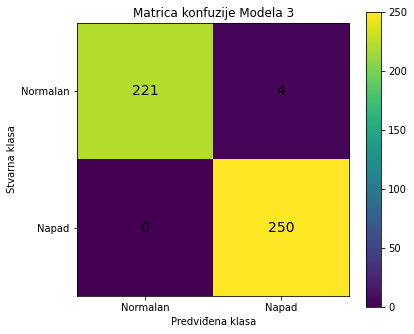

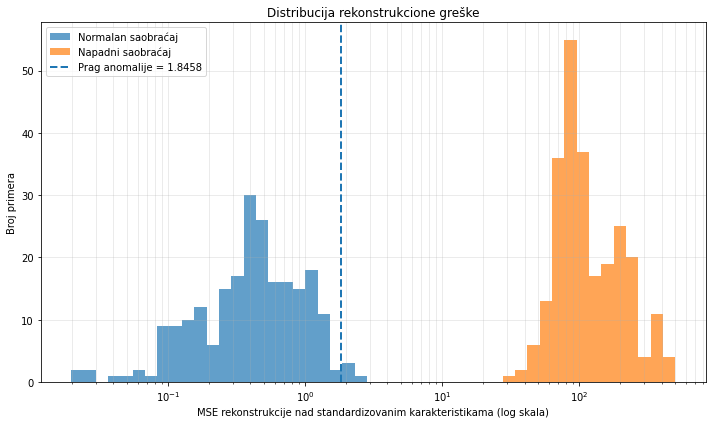

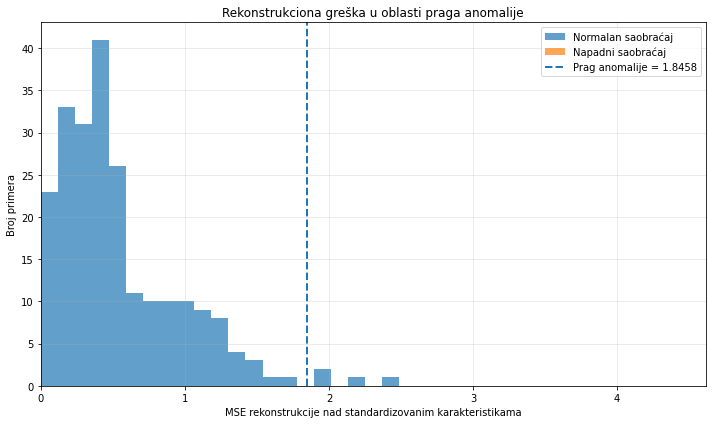

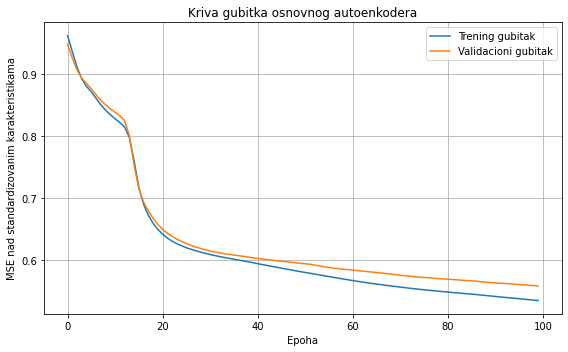

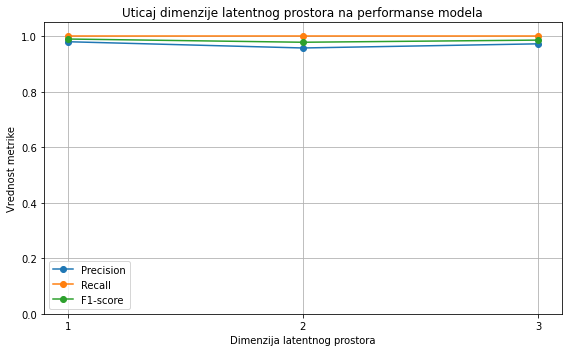

In [12]:
model_3 = experiment_results["Model 3"]
base_run = trained_runs["base_latent_2"]

cm_model_3 = confusion_matrix(
    y_test,
    model_3["y_pred"],
    labels=[0, 1]
)

plot_confusion_matrix(
    cm=cm_model_3,
    labels=["Normalan", "Napad"],
    title="Matrica konfuzije Modela 3",
    filename="confusion_matrix_model_3.png"
)

plot_reconstruction_errors_log(
    test_errors=model_3["test_errors"],
    labels=y_test,
    threshold=model_3["result"]["threshold"],
    title="Distribucija rekonstrukcione greške",
    filename="reconstruction_error_log_model_3.png"
)

plot_reconstruction_errors_zoom(
    test_errors=model_3["test_errors"],
    labels=y_test,
    threshold=model_3["result"]["threshold"],
    title="Rekonstrukciona greška u oblasti praga anomalije",
    filename="reconstruction_error_zoom_model_3.png"
)

plot_training_history(
    history=base_run["history"],
    title="Kriva gubitka osnovnog autoenkodera",
    filename="training_loss_base_autoencoder.png"
)

plot_latent_dimension_metrics(
    latent_df=latent_comparison_df,
    filename="latent_dimension_metrics.png"
)


## 9. Result summary


In [13]:
columns_for_paper = [
    "model",
    "architecture",
    "threshold_percentile",
    "threshold",
    "accuracy",
    "precision",
    "recall",
    "f1_score",
    "roc_auc",
    "tn",
    "fp",
    "fn",
    "tp"
]

print("OSNOVNI MODELI")
display(main_comparison_df[columns_for_paper])

print("LATENTNE DIMENZIJE")
display(latent_comparison_df[columns_for_paper])

print("Završeno treniranje, evaluacija i čuvanje rezultata.")


OSNOVNI MODELI


,model,architecture,threshold_percentile,threshold,accuracy,precision,recall,f1_score,roc_auc,tn,fp,fn,tp
0,Model 1,5-8-4-2-4-8-5,95,1.353162,0.976842,0.957854,1.0,0.978474,1.0,214,11,0,250
1,Model 2,5-4-2-4-5,95,1.392840,0.972632,0.950570,1.0,0.974659,1.0,212,13,0,250
2,Model 3,5-8-4-2-4-8-5,99,1.845839,0.991579,0.984252,1.0,0.992063,1.0,221,4,0,250


LATENTNE DIMENZIJE


,model,architecture,threshold_percentile,threshold,accuracy,precision,recall,f1_score,roc_auc,tn,fp,fn,tp
0,Latent 1,5-8-4-1-4-8-5,95,1.803629,0.989474,0.980392,1.0,0.990099,1.0,220,5,0,250
1,Latent 2,5-8-4-2-4-8-5,95,1.353162,0.976842,0.957854,1.0,0.978474,1.0,214,11,0,250
2,Latent 3,5-8-4-3-4-8-5,95,1.473187,0.985263,0.972763,1.0,0.986193,1.0,218,7,0,250


Završeno treniranje, evaluacija i čuvanje rezultata.
